<a href="https://colab.research.google.com/github/thaslima921/Cat2/blob/main/Traffic_Volume.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# TASK 1: LOAD AND PREPROCESS DATA

import zipfile
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

# Upload archive.zip
uploaded = files.upload()
zip_path = next(iter(uploaded))

# Read Train.csv directly from the ZIP
with zipfile.ZipFile(zip_path, "r") as z:
    csv_names = z.namelist()
    print("ZIP files:", csv_names)

    train_file = next(
        (n for n in csv_names if n.split("/")[-1].lower() == "train.csv"),
        None
    )

    if train_file is None:
        raise ValueError("Train.csv was not found inside the ZIP file.")

    with z.open(train_file) as f:
        raw = pd.read_csv(f)

raw.columns = raw.columns.str.strip().str.lower()

required = {"date_time", "traffic_volume"}
if not required.issubset(raw.columns):
    raise ValueError(f"Missing required columns: {required - set(raw.columns)}")

raw["date_time"] = pd.to_datetime(raw["date_time"], errors="coerce")
raw["traffic_volume"] = pd.to_numeric(
    raw["traffic_volume"], errors="coerce"
)

raw = raw.dropna(subset=["date_time", "traffic_volume"])
raw = raw.sort_values("date_time")

print("\nOriginal valid training rows:", len(raw))
print("Duplicate timestamps:", raw["date_time"].duplicated().sum())

# Keep numerical weather features and target.
# Categorical weather descriptions are not needed for this compact model.
numeric_columns = raw.select_dtypes(include=np.number).columns.tolist()

if "traffic_volume" not in numeric_columns:
    raise ValueError("traffic_volume must be numeric.")

# Aggregate repeated timestamps instead of counting them as separate hours.
df = raw.groupby("date_time", sort=True)[numeric_columns].mean()

# Create a regular hourly timeline.
hourly_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

data = df.reindex(hourly_index)
data.index.name = "date_time"

# Report which hours lack original traffic observations.
missing_hours_total = int(data["traffic_volume"].isna().sum())
observed_hours_total = int(data["traffic_volume"].notna().sum())

print("Unique observed traffic hours:", observed_hours_total)
print("Missing traffic hours before filling:", missing_hours_total)

# Fill missing values to create a continuous series.
# Interpolated values are estimates, not genuine observations.
data["traffic_volume"] = data["traffic_volume"].interpolate(
    method="time", limit_direction="both"
)

# Use only numeric weather columns available in the uploaded file.
weather_candidates = [
    "temperature",
    "humidity",
    "wind_speed",
    "wind_direction",
    "air_pollution_index",
    "rain_p_h",
    "snow_p_h",
    "clouds_all",
    "visibility_in_miles",
    "dew_point"
]

weather_features = [
    c for c in weather_candidates if c in data.columns
]

for col in weather_features:
    data[col] = data[col].interpolate(
        method="time", limit_direction="both"
    )
    data[col] = data[col].fillna(data[col].median()).fillna(0)

# Select the first 20,000 chronological hourly timestamps.
N = 20000

if len(data) < N:
    raise ValueError(
        f"Only {len(data)} hourly timestamps are available; "
        f"{N} are required."
    )

data = data.iloc[:N].copy()

# Encode daily and weekly time patterns.
data["hour_sin"] = np.sin(2 * np.pi * data.index.hour / 24)
data["hour_cos"] = np.cos(2 * np.pi * data.index.hour / 24)
data["weekday_sin"] = np.sin(
    2 * np.pi * data.index.dayofweek / 7
)
data["weekday_cos"] = np.cos(
    2 * np.pi * data.index.dayofweek / 7
)

features = [
    "traffic_volume"
] + weather_features + [
    "hour_sin", "hour_cos", "weekday_sin", "weekday_cos"
]

data[features] = data[features].replace(
    [np.inf, -np.inf], np.nan
)
data[features] = data[features].ffill().bfill().fillna(0)

# Final checks
assert len(data) == 20000
assert data.index.is_monotonic_increasing
assert data.index.to_series().diff().dropna().eq(
    pd.Timedelta(hours=1)
).all()
assert data[features].isna().sum().sum() == 0

print("\n========== TASK 1 COMPLETED ==========")
print("Selected hourly timestamps:", len(data))
print("Time range:", data.index.min(), "to", data.index.max())
print("Observed hours in original timeline:", observed_hours_total)
print("Missing hours filled in original timeline:", missing_hours_total)
print("Features:", features)
print("Dataset shape:", data[features].shape)

display(data[features].head())


TensorFlow version: 2.21.0
GPU available: True


Saving archive.zip to archive.zip
ZIP files: ['Test.csv', 'Train.csv', 'sample_submission.csv']

Original valid training rows: 33750
Duplicate timestamps: 5161
Unique observed traffic hours: 28589
Missing traffic hours before filling: 11938

========== TASK 1 COMPLETED ==========
Selected hourly timestamps: 20000
Time range: 2012-10-02 09:00:00 to 2015-01-13 16:00:00
Observed hours in original timeline: 28589
Missing hours filled in original timeline: 11938
Features: ['traffic_volume', 'temperature', 'humidity', 'wind_speed', 'wind_direction', 'air_pollution_index', 'rain_p_h', 'snow_p_h', 'clouds_all', 'visibility_in_miles', 'dew_point', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos']
Dataset shape: (20000, 15)


,traffic_volume,temperature,humidity,wind_speed,wind_direction,air_pollution_index,rain_p_h,snow_p_h,clouds_all,visibility_in_miles,dew_point,hour_sin,hour_cos,weekday_sin,weekday_cos
date_time,,,,,,,,,,,,,,,
2012-10-02 09:00:00,5545.0,288.28,89.0,2.0,329.0,121.0,0.0,0.0,40.0,1.0,1.0,7.071068e-01,-0.707107,0.781831,0.62349
2012-10-02 10:00:00,4516.0,289.36,67.0,3.0,330.0,178.0,0.0,0.0,75.0,1.0,1.0,5.000000e-01,-0.866025,0.781831,0.62349
2012-10-02 11:00:00,4767.0,289.58,66.0,3.0,329.0,113.0,0.0,0.0,90.0,2.0,2.0,2.588190e-01,-0.965926,0.781831,0.62349
2012-10-02 12:00:00,5026.0,290.13,66.0,3.0,329.0,20.0,0.0,0.0,90.0,5.0,5.0,1.224647e-16,-1.000000,0.781831,0.62349
2012-10-02 13:00:00,4918.0,291.14,65.0,3.0,329.0,281.0,0.0,0.0,75.0,7.0,7.0,-2.588190e-01,-0.965926,0.781831,0.62349


In [2]:

# TASK 2: CREATE SEQUENTIAL WINDOWS

from numpy.lib.stride_tricks import sliding_window_view

LOOKBACK = 24
split = int(len(data) * 0.80)
target_idx = features.index("traffic_volume")

values = data[features].to_numpy(dtype=np.float32)

# Fit scalers on training-period data only.
x_scaler = StandardScaler()
y_scaler = StandardScaler()

x_scaler.fit(values[:split])
y_scaler.fit(values[:split, target_idx].reshape(-1, 1))

X_scaled = x_scaler.transform(values).astype(np.float32)
y_scaled = y_scaler.transform(
    values[:, target_idx].reshape(-1, 1)
).ravel().astype(np.float32)

# Shape: (samples, 24 hours, features)
X_all = sliding_window_view(
    X_scaled, window_shape=LOOKBACK, axis=0
).transpose(0, 2, 1)[:-1]

# Target is the hour immediately following each input window.
y_all = y_scaled[LOOKBACK:]
target_positions = np.arange(LOOKBACK, len(data))

train_mask = target_positions < split
test_mask = target_positions >= split

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

test_timestamps = data.index[target_positions[test_mask]]

print("========== TASK 2 COMPLETED ==========")
print("Input window:", LOOKBACK, "hours")
print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)
print("Testing inputs:", X_test.shape)
print("Testing targets:", y_test.shape)

assert X_train.ndim == 3
assert X_train.shape[1] == LOOKBACK
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert len(X_test) > 0


========== TASK 2 COMPLETED ==========
Input window: 24 hours
Training inputs: (15976, 24, 15)
Training targets: (15976,)
Testing inputs: (4000, 24, 15)
Testing targets: (4000,)


Epoch 1/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy_within_10_percent: 6.2665 - loss: 0.3945 - mae: 0.4834 - val_accuracy_within_10_percent: 7.6651 - val_loss: 0.2411 - val_mae: 0.3614
Epoch 2/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy_within_10_percent: 7.2935 - loss: 0.1843 - mae: 0.3179 - val_accuracy_within_10_percent: 8.0350 - val_loss: 0.1781 - val_mae: 0.3092
Epoch 3/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy_within_10_percent: 7.3959 - loss: 0.1434 - mae: 0.2790 - val_accuracy_within_10_percent: 8.5121 - val_loss: 0.1464 - val_mae: 0.2771
Epoch 4/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy_within_10_percent: 7.4848 - loss: 0.1143 - mae: 0.2480 - val_accuracy_within_10_percent: 8.5971 - val_loss: 0.1230 - val_mae: 0.2508
Epoch 5/8
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy_within_10_percent: 7.5172 - loss: 0.0931 - mae: 0.2247 - val_accuracy_within_10_percent: 8.4748 - val_loss: 0.1101 - val_mae: 0.2366
Epoch 6/8
113/113 ━━━━━

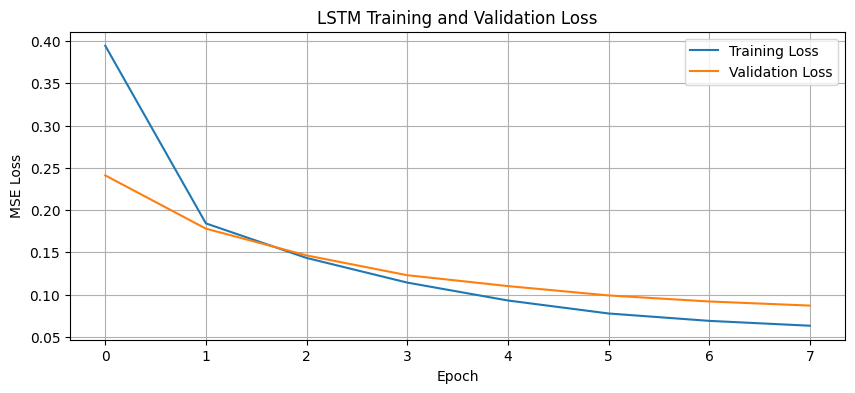

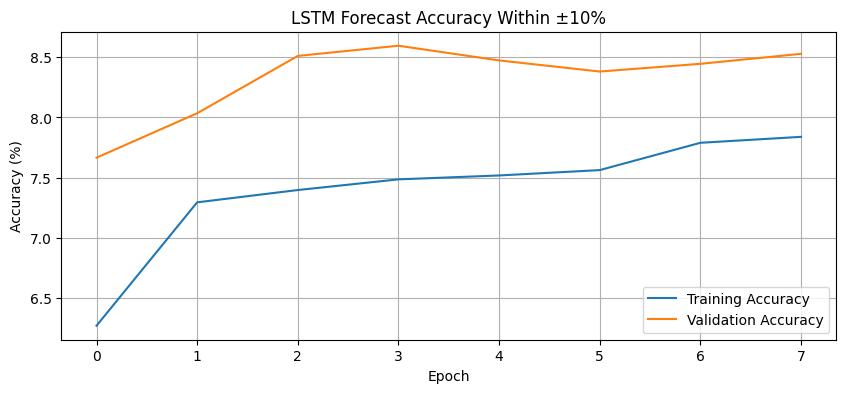

In [5]:

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
import time
import matplotlib.pyplot as plt

# Custom accuracy: prediction is correct if within 10% of actual value
def accuracy_within_10_percent(y_true, y_pred):
    tolerance = 0.10 * tf.maximum(tf.abs(y_true), 1.0)
    correct = tf.abs(y_true - y_pred) <= tolerance
    return tf.reduce_mean(tf.cast(correct, tf.float32)) * 100.0

# Build LSTM model
model = Sequential([
    Input(shape=(LOOKBACK, len(features))),
    LSTM(32),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dense(1)
])

# Compile with loss, MAE, and custom accuracy
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae", accuracy_within_10_percent]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=8,
    batch_size=128,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("\n========== TASK 3 RESULTS ==========")
print(f"Training time: {(time.time() - start_time) / 60:.2f} minutes")

# Print results for every epoch
print("\nEpoch-wise Loss and Accuracy")
print("-" * 90)

for i in range(len(history.history["loss"])):
    print(
        f"Epoch {i+1:02d} | "
        f"Loss: {history.history['loss'][i]:.4f} | "
        f"Val Loss: {history.history['val_loss'][i]:.4f} | "
        f"Accuracy: {history.history['accuracy_within_10_percent'][i]:.2f}% | "
        f"Val Accuracy: {history.history['val_accuracy_within_10_percent'][i]:.2f}%"
    )

# Plot loss
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot custom accuracy
plt.figure(figsize=(10, 4))
plt.plot(
    history.history["accuracy_within_10_percent"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy_within_10_percent"],
    label="Validation Accuracy"
)
plt.title("LSTM Forecast Accuracy Within ±10%")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.show()


In [6]:

# TASK 4: EVALUATE MODEL

pred_scaled = model.predict(
    X_test, batch_size=256, verbose=0
).reshape(-1, 1)

y_pred = y_scaler.inverse_transform(pred_scaled).ravel()
y_actual = y_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("\n========== TASK 4: EVALUATION RESULTS ==========")
print(f"MAE  : {mae:.2f} vehicles/hour")
print(f"RMSE : {rmse:.2f} vehicles/hour")
print("Number of test predictions:", len(y_actual))

results = pd.DataFrame({
    "date_time": test_timestamps,
    "actual_traffic": y_actual,
    "predicted_traffic": y_pred
})

display(results.head(10))



========== TASK 4: EVALUATION RESULTS ==========
MAE  : 631.67 vehicles/hour
RMSE : 841.04 vehicles/hour
Number of test predictions: 4000


,date_time,actual_traffic,predicted_traffic
0,2014-07-31 01:00:00,485.000031,598.754395
1,2014-07-31 02:00:00,330.000031,404.303009
2,2014-07-31 03:00:00,424.000031,407.466827
3,2014-07-31 04:00:00,984.000000,912.318359
4,2014-07-31 05:00:00,3154.000000,2366.475830
5,2014-07-31 06:00:00,5633.000000,5070.596191
6,2014-07-31 07:00:00,6739.000000,6105.094238
7,2014-07-31 08:00:00,6211.000000,5680.311035
8,2014-07-31 09:00:00,5577.000000,5301.596191
9,2014-07-31 10:00:00,4977.000000,4963.965332


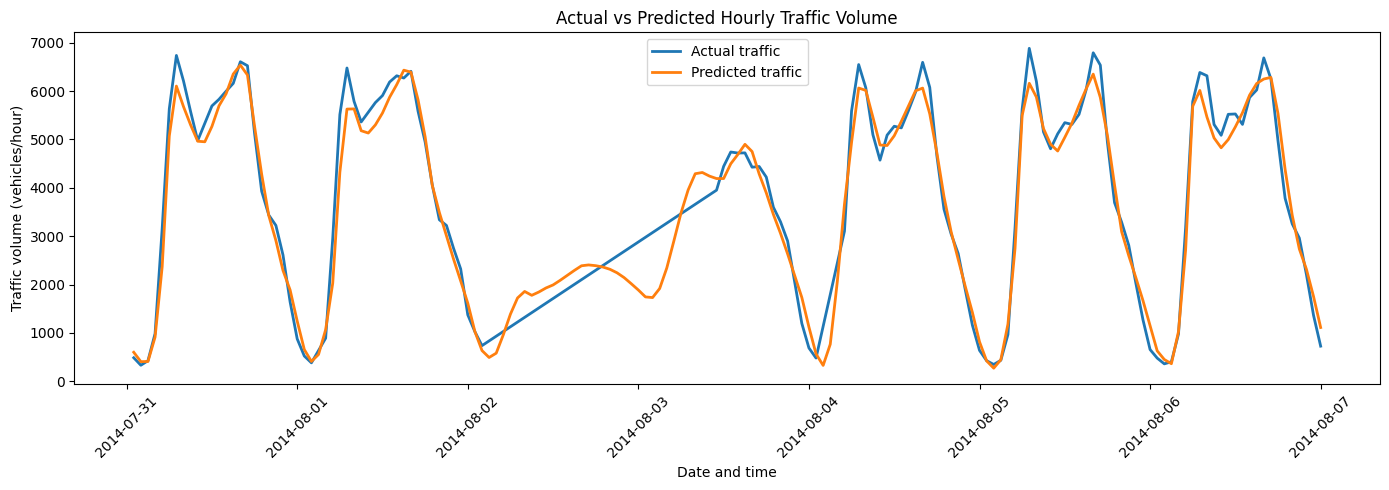

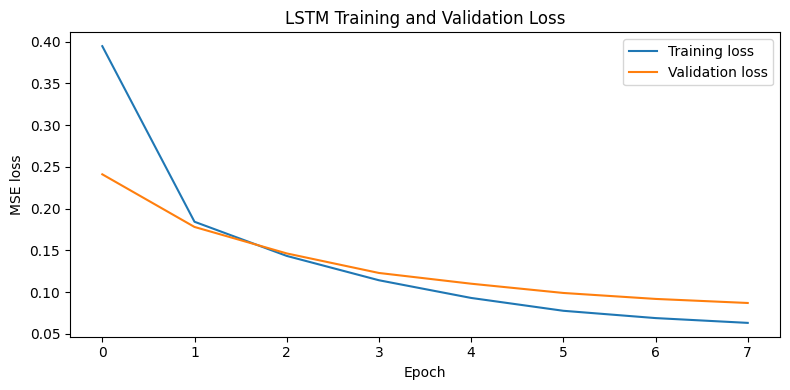


========== TASK 5: PLANNING DEMONSTRATION ==========
Illustrative high-traffic threshold: 1464 vehicles/hour


,date_time,actual_traffic,predicted_traffic,planning_alert
0,2014-07-31 01:00:00,485.000031,598.754395,NORMAL - Routine monitoring
1,2014-07-31 02:00:00,330.000031,404.303009,NORMAL - Routine monitoring
2,2014-07-31 03:00:00,424.000031,407.466827,NORMAL - Routine monitoring
3,2014-07-31 04:00:00,984.000000,912.318359,NORMAL - Routine monitoring
4,2014-07-31 05:00:00,3154.000000,2366.475830,HIGH TRAFFIC - Consider extra monitoring
5,2014-07-31 06:00:00,5633.000000,5070.596191,HIGH TRAFFIC - Consider extra monitoring
6,2014-07-31 07:00:00,6739.000000,6105.094238,HIGH TRAFFIC - Consider extra monitoring
7,2014-07-31 08:00:00,6211.000000,5680.311035,HIGH TRAFFIC - Consider extra monitoring
8,2014-07-31 09:00:00,5577.000000,5301.596191,HIGH TRAFFIC - Consider extra monitoring
9,2014-07-31 10:00:00,4977.000000,4963.965332,HIGH TRAFFIC - Consider extra monitoring


Saved predictions to traffic_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

# TASK 5: VISUALIZATION AND TRAFFIC PLANNING

# Plot the first 7 days of the test period.
plot_n = min(168, len(results))

plt.figure(figsize=(14, 5))
plt.plot(
    results["date_time"].iloc[:plot_n],
    results["actual_traffic"].iloc[:plot_n],
    label="Actual traffic",
    linewidth=2
)
plt.plot(
    results["date_time"].iloc[:plot_n],
    results["predicted_traffic"].iloc[:plot_n],
    label="Predicted traffic",
    linewidth=2
)

plt.title("Actual vs Predicted Hourly Traffic Volume")
plt.xlabel("Date and time")
plt.ylabel("Traffic volume (vehicles/hour)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot training and validation loss.
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.tight_layout()
plt.show()

# Demonstration traffic alert.
# This is a sample threshold, not a verified road-capacity limit.
threshold = np.quantile(y_actual, 0.75)

planning = results[["date_time", "actual_traffic", "predicted_traffic"]].copy()
planning["planning_alert"] = np.where(
    planning["predicted_traffic"] >= threshold,
    "HIGH TRAFFIC - Consider extra monitoring",
    "NORMAL - Routine monitoring"
)

print("\n========== TASK 5: PLANNING DEMONSTRATION ==========")
print(f"Illustrative high-traffic threshold: {threshold:.0f} vehicles/hour")
display(planning.head(24))

# Save prediction results for your report.
results.to_csv("traffic_predictions.csv", index=False)
print("Saved predictions to traffic_predictions.csv")

files.download("traffic_predictions.csv")
